In [ ]:

pip install tensorflow matplotlib scikit-image


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 54.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 79.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 77.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 95.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.2 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D

def build_denoising_autoencoder(input_shape=(64, 64, 1)):
    input_img = Input(shape=input_shape)

    # Encoder
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)

    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    encoded = MaxPooling2D((2, 2), padding='same')(x)

    # Decoder
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(encoded)
    x = UpSampling2D((2, 2))(x)

    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)

    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    return Model(input_img, decoded)


In [ ]:
import numpy as np
from skimage.util import random_noise

def add_noise(images):
    noisy = []
    for img in images:
        noisy_img = random_noise(img, mode='gaussian', var=0.01)
        noisy.append(noisy_img)
    return np.array(noisy)

In [ ]:
from google.colab import drive
import os

# Mount your Google Drive
try:
    from google.colab import drive
    if not os.path.exists('../data'):
        drive.mount('/content/drive')
except Exception:
    pass

# Path to the "IMG" folder in your Google Drive
img_folder_path = '../data/IMG'

# List all files in the IMG folder
img_files = os.listdir(img_folder_path)
print("Files in IMG folder:", img_files)

# If needed, you can loop through and process them:
for file in img_files:
    print(file)


Mounted at /content/drive
Files in IMG folder: ['Full 1.png', 'Full 2.png']
Full 1.png
Full 2.png


In [ ]:
!pip install opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 MB 20.5 MB/s eta 0:00:00


In [ ]:
!pip install tensorflow matplotlib scikit-image opencv-python

In [ ]:
import os
import cv2
import numpy as np
from google.colab import drive

def load_dataset(patch_size=64, stride=64, max_patches=500):
    # 1. Mount Drive (only once per session)
    drive.mount('/content/drive', force_remount=False)

    # 2. Define helper functions
    def load_and_preprocess_image(path):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise FileNotFoundError(f"Image not found at {path}")
        img = img.astype('float32') / 255.0
        return img

    def extract_patches(img, patch_size, stride, max_patches=None):
        patches = []
        h, w = img.shape
        for i in range(0, h - patch_size + 1, stride):
            for j in range(0, w - patch_size + 1, stride):
                patch = img[i:i+patch_size, j:j+patch_size]
                patches.append(patch[..., np.newaxis])  # Add channel dim
                if max_patches is not None and len(patches) >= max_patches:
                    return np.array(patches)
        return np.array(patches)

    # 3. Set file paths
    img_folder = '../data/IMG'
    noisy_path = os.path.join(img_folder, 'Full 1.png')
    clean_path = os.path.join(img_folder, 'Full 2.png')

    # 4. Load and preprocess full images
    noisy_img = load_and_preprocess_image(noisy_path)
    clean_img = load_and_preprocess_image(clean_path)

    # 5. Extract patches
    x_train_noisy = extract_patches(noisy_img, patch_size, stride, max_patches)
    x_train_clean = extract_patches(clean_img, patch_size, stride, max_patches)

    # 6. Return ready-to-train arrays
    print(f"Noisy patches: {x_train_noisy.shape}")
    print(f"Clean patches: {x_train_clean.shape}")
    return x_train_noisy.astype('float32'), x_train_clean.astype('float32')

# Use like this
x_train_noisy, x_train_clean = load_dataset()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Noisy patches: (500, 64, 64, 1)
Clean patches: (500, 64, 64, 1)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 502ms/step - loss: 0.5838 - val_loss: 0.3379
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 452ms/step - loss: 0.3960 - val_loss: 0.3275
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 417ms/step - loss: 0.3901 - val_loss: 0.3294
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 438ms/step - loss: 0.3860 - val_loss: 0.3130
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 409ms/step - loss: 0.3825 - val_loss: 0.3024
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 410ms/step - loss: 0.3803 - val_loss: 0.3011
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 403ms/step - loss: 0.3783 - val_loss: 0.3003
Epoch 8/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 417ms/step - loss: 0.3779 - val_loss: 0.2994
Epoch 9/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 410ms/step - loss: 0.3779 - val_loss: 0.2988
Epoch 10/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 409ms/step - loss: 0.3791 - val_loss: 0.2985
Epoch 11/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 409ms/step - loss: 0.3785 - val_loss: 0.2984
Epoch 12/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 403ms/step

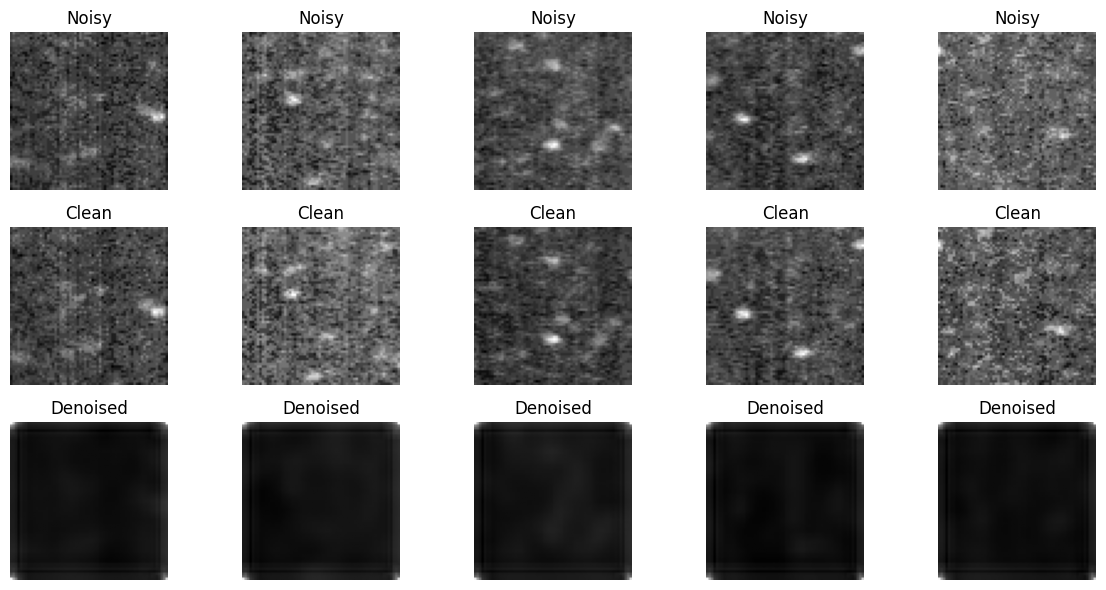

In [ ]:
# 1. Build & compile the model
autoencoder = build_denoising_autoencoder()
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')
autoencoder.summary()

# 2. Train the model
history = autoencoder.fit(
    x_train_noisy, x_train_clean,
    epochs=20,
    batch_size=32,
    shuffle=True,
    validation_split=0.1
)

# 3. Visualize predictions on a few test patches
import matplotlib.pyplot as plt

# Predict on first 10 noisy patches
decoded_imgs = autoencoder.predict(x_train_noisy[:10])

# Plot
n = 5  # Show 5 samples
plt.figure(figsize=(12, 6))
for i in range(n):
    # Noisy Input
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_train_noisy[i].reshape(64, 64), cmap='gray')
    plt.title("Noisy")
    plt.axis("off")

    # Clean Ground Truth
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_train_clean[i].reshape(64, 64), cmap='gray')
    plt.title("Clean")
    plt.axis("off")

    # Autoencoder Output
    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_imgs[i].reshape(64, 64), cmap='gray')
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()


The denoising autoencoder helps enhance faint or broken lines by learning to reconstruct clean versions of noisy images. By removing background noise and reinforcing line structures, it makes faint lines more visible and continuous. This significantly improves the performance of traditional detectors like Hough or Canny, which often miss such features in raw images. Without requiring manual annotation, it serves as a powerful preprocessing step, enabling more reliable line detection on challenging “Bad Images” while keeping the pipeline simple and scalable.

In [ ]:
x_train_noisy.shape  # e.g. (500, 64, 64, 1)


(500, 64, 64, 1)

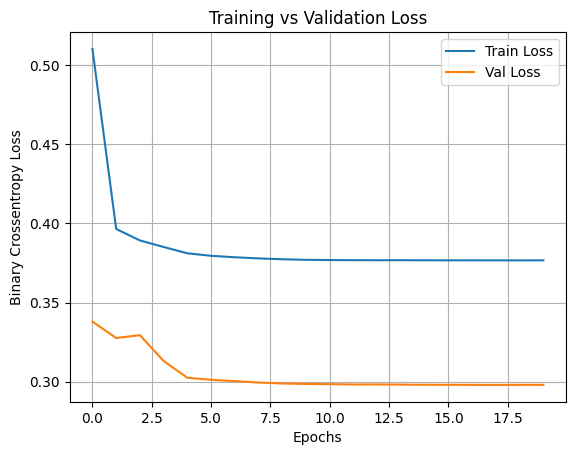

In [ ]:
# Plot loss curve
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Binary Crossentropy Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
loss = autoencoder.evaluate(x_train_noisy, x_train_clean)
print(f"Reconstruction Loss (Binary Crossentropy): {loss:.4f}")


16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 154ms/step - loss: 0.3720
Reconstruction Loss (Binary Crossentropy): 0.3688
